In [1]:
import os
import sys
sys.path.insert(0, "./../../Python/cellular_cycle") # add path to the model

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
from pathlib import Path
import datetime
import pickle
import glob
import joblib
import umap
from statistics import mean

## Importing the model, models differ on their initial conditions, one being a concentration and the other a protein count

# to match Austin's ouput and use his functions, simulation with ODE should use omega=1 and stochastic with omega=200 (the default)
from cell_cycle_death_model import model
from model_fxns import * # functions to evaluate simulation output; includes plotObs()

##Import the simulator: for ODE and stochastic simulation :
from pysb.simulator import BngSimulator
from pysb.simulator import ScipyOdeSimulator


# Directory containing cell fate data
#DATADIR = Path('../data/Exp_Intermitotic_Times/')

# Where to save large simulation output files
SAVE_DIR = Path(Path.home(),'ECM_mod_output/dist_runs/')
#SAVE_DIR = Path(Path.home(),'ECM_mod_output')
if not SAVE_DIR.exists():
    SAVE_DIR.mkdir()

OVERWRITE = False # Overwrite existing simulation files

CURDATE = datetime.datetime.now().strftime('%Y%m%d')

In [2]:
# t = np.linspace(0, 10000, 100001)
t = np.linspace(0, 20000, 200001)
# t = np.linspace(0, 50000, 500001)

model.parameters['AKT'].value = 1
model.parameters['ERK'].value = 1
model.parameters['FAK'].value = 0.6

In [10]:
# Importing the parameters:
new_param = pd.read_csv(os.getcwd()+ '/../../Python/model_data/parameters.csv')
for key in new_param.keys():
    try:
        if model.parameters[key].value != new_param[key][0]:
            model.parameters[key].value = new_param[key]
    except:
        print(key)
model.parameters['omega'].value = 200

Unnamed: 0


In [11]:
sim_ode = ScipyOdeSimulator(model, t, verbose=False, compiler='python').run(); #deterministic simulation

<Axes: xlabel='Time (h)', ylabel='Concentration'>

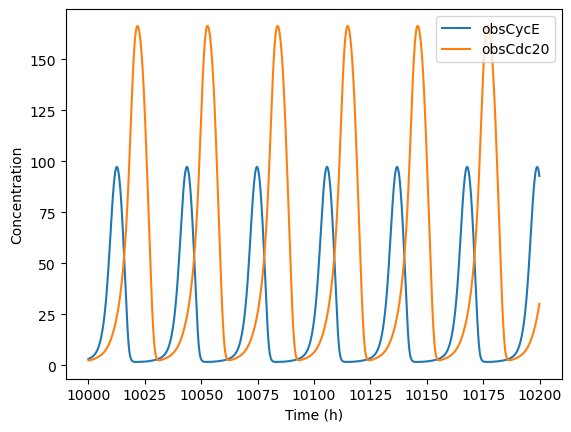

In [12]:
observables=['obsCycE','obsCdc20']; #plot Cyclin E, Cdc20 and Cyclin A

plotObs(model=sim_ode.all, obs=observables, times=t, tpos=range(100000,102000), legend=True)


In [13]:
FAKs = list(np.linspace(0.4,0.6,50))
tmp = list(np.linspace(0.6,1,50))
FAKs.extend(tmp)
AKTs = list(np.linspace(0.6,1,50))
tmp = [1]*50
AKTs.extend(tmp)
ERKs = [1]*100

In [20]:
FAKs = list(np.linspace(0.4,0.6,50))
tmp = list(np.linspace(0.6,1,50))
FAKs.extend(tmp)
AKTs = list(np.linspace(0.3,0.6,50))
tmp = [0.6]*50
AKTs.extend(tmp)
ERKs = [0.2]*100

In [21]:
model.parameters['FAK'].value = FAKs[24]
model.parameters['AKT'].value = AKTs[24]
model.parameters['ERK'].value = ERKs[24]

In [22]:
simres = ScipyOdeSimulator(model, t, verbose=False, compiler='python').run(); #deterministic simulation
yout = simres.observables;
filename = Path(SAVE_DIR, f'ODE_sim_erl_stiff025_orig.csv')
np.savetxt(filename, yout, delimiter=',')

In [23]:
sim = BngSimulator(model, tspan=t, verbose=False) #stochastic simulator
simres = sim.run(method='ssa', verbose=False, seed=33) #running the simulation; remove seed for truly random; seed=33 is used for similarity to deterministic sim
yout = simres.observables
filename = Path(SAVE_DIR, f'stoch_sim_erl_stiff025_orig.csv')
np.savetxt(filename, yout, delimiter=',')

In [24]:
model.parameters['FAK'].value = FAKs[74]
model.parameters['AKT'].value = AKTs[74]
model.parameters['ERK'].value = ERKs[74]

In [25]:
simres = ScipyOdeSimulator(model, t, verbose=False, compiler='python').run(); #deterministic simulation
yout = simres.observables;
filename = Path(SAVE_DIR, f'ODE_sim_erl_stiff075_orig.csv')
np.savetxt(filename, yout, delimiter=',')

sim = BngSimulator(model, tspan=t, verbose=False) #stochastic simulator
simres = sim.run(method='ssa', verbose=False, seed=33) #running the simulation; remove seed for truly random; seed=33 is used for similarity to deterministic sim
yout = simres.observables
filename = Path(SAVE_DIR, f'stoch_erl_stiff075_orig.csv')
np.savetxt(filename, yout, delimiter=',')

### Load Data

In [81]:
file_location = os.path.join('C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\', 'stoch_sim*jparam0.csv')
filenames = glob.glob(file_location)
filenames = sorted(filenames)
# filenames_sp = [filenames[5], filenames[6], filenames[3], filenames[4], filenames[7], filenames[8], 
#                filenames[0], filenames[1], filenames[2]]

# filenames_sp = [filenames[0], filenames[4], filenames[9],
#                 filenames[13], filenames[14], filenames[20], filenames[26]]

# filenames_conds = [filenames[0], filenames[6], filenames[13],
#                 filenames[14], filenames[20], filenames[26]]

filenames_sp = [filenames[0], filenames[2], filenames[4],
                filenames[5], filenames[7], filenames[9]]
filenames_sp = filenames
filenames_sp


['C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\stoch_sim_dmso_stiff001_jparam0.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\stoch_sim_dmso_stiff025_jparam0.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\stoch_sim_dmso_stiff050_jparam0.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\stoch_sim_dmso_stiff075_jparam0.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\stoch_sim_dmso_stiff100_jparam0.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\stoch_sim_erl_stiff001_jparam0.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\stoch_sim_erl_stiff025_jparam0.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\stoch_sim_erl_stiff050_jparam0.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\stoch_sim_erl_stiff075_jparam0.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\stoch_sim_erl_stiff100_jparam0.csv']

In [145]:
file_location = os.path.join('C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\', 'ODE_sim*jparam0.csv')
filenames_ode = glob.glob(file_location)
filenames_ode = sorted(filenames_ode)
# filenames_sp_ode = [filenames_ode[0], filenames_ode[4], filenames_ode[9],
#                     filenames_ode[13], filenames_ode[14], filenames_ode[20], filenames_ode[27]]

# filenames_conds_ode = [filenames_ode[0], filenames_ode[6], filenames_ode[13],
#                     filenames_ode[14], filenames_ode[20], filenames_ode[27]]

filenames_sp_ode = [filenames_ode[0], filenames_ode[2], filenames_ode[4],
                    filenames_ode[5], filenames_ode[7], filenames_ode[9]]

filenames_sp_ode = filenames_ode
filenames_sp_ode


['C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\ODE_sim_dmso_stiff001_jparam0.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\ODE_sim_dmso_stiff025_jparam0.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\ODE_sim_dmso_stiff050_jparam0.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\ODE_sim_dmso_stiff075_jparam0.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\ODE_sim_dmso_stiff100_jparam0.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\ODE_sim_erl_stiff001_jparam0.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\ODE_sim_erl_stiff025_jparam0.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\ODE_sim_erl_stiff050_jparam0.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\ODE_sim_erl_stiff075_jparam0.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\ODE_sim_erl_stiff100_jparam0.csv']

In [50]:
#The filenames to make the reducer umap object from
"""
filenames = ['erl_4-9_1_1.txt', 'erl_4-9_2_1.txt', 'erl_4-9_3_1.txt',
             'dmso_4-9_1_1.txt', 'dmso_4-9_2_1.txt', 'dmso_4-9_3_1.txt']
#Important params to set the window size and step time distance
init_dt = 0.01                #initial dt from the raw model output
dt = 0.1                      #dt for umap window
window = 4                    #window size in hours
time_step = 1                 #time step between windows

#umap params
neighbs = 100
min_d = 0.02
"""
# Important params to set the window size and step time distance
init_dt = 0.1                # initial dt from the raw model output
dt = 0.1                      # dt for umap window
window = 4                    # window size in hours
time_step = 0.5               # time step between windows

#umap params
neighbs = 25
min_d = 0.05

#reducer save name
r_name = f'reducer_01_04_{init_dt}_{dt}_{window}_{time_step}.sav'

In [51]:
def calc_minmax(filenames, filenames_ode):
    max_prots=[0]*18
    min_prots=[1000]*18
    
    for f in filenames:
        tmp_max=[]
        tmp_min=[]
        prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp = prot_tmp.drop(columns=['cdh1_inact'])
        #prot_tmp = prot_tmp/200
        prot_tmp[prot_tmp<0] = 0 #from old extrap. method, don't think I need this
        
        tmp_max = [prot_tmp[col].max() for col in prot_tmp]
        tmp_min = [prot_tmp[col].min() for col in prot_tmp]
        
        max_prots = [max(max_prots[n], tmp_max[n]) for n in range(18)]
        min_prots = [min(min_prots[n], tmp_min[n]) for n in range(18)]
        
    for f in filenames_ode:
        tmp_max=[]
        tmp_min=[]
        prot_tmp_ode = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp_ode.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp_ode = prot_tmp_ode.drop(columns=['cdh1_inact'])
        prot_tmp[prot_tmp<0] = 0 #from old extrap. method, don't think I need this
        
        tmp_max = [prot_tmp_ode[col].max() for col in prot_tmp_ode]
        tmp_min = [prot_tmp_ode[col].min() for col in prot_tmp_ode]
        
        max_prots = [max(max_prots[n], tmp_max[n]) for n in range(18)]
        min_prots = [min(min_prots[n], tmp_min[n]) for n in range(18)]  
        
    return max_prots, min_prots

In [52]:
def load_norm_data(filenames, filenames_ode, max_prots, min_prots, time_all, init_dt, dt, window, time_step, plot_phase):
     
    if plot_phase:
        plot_phase(filenames_sp, filenames_sp_ode)
        plt.savefig(SAVE_DIR + f"phaseplot_{num}.png", bbox_inches='tight')
        plot_phase_norm(filenames_sp, filenames_sp_ode, max_prots, min_prots)
        plt.savefig(SAVE_DIR + f"phaseplot_norm_{num}.png", bbox_inches='tight')
    
    win_len = int(window/dt)
    all_prot_tmp = np.empty((0,win_len*18))     #careful, this could end up being massive 
    all_prot_tmp_ode = np.empty((0,win_len*18))
    all_time_tmp = np.empty((0,win_len))
    all_time_at_tmp = np.empty((0,1))
    range_ind = np.arange(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt))
        
    for (f, f_ode) in zip(filenames, filenames_ode):
        prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp = prot_tmp.drop(columns=['cdh1_inact'])
        #prot_tmp = prot_tmp/200
        for ii in range(18):
            prot_tmp.iloc[:,ii] = (prot_tmp.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])

        prot_re_tmp = np.empty((len(range_ind),win_len*18))
        time_re_tmp = np.empty((len(range_ind),win_len))
        time_at_tmp = np.empty((len(range_ind),1))

        ii=0
        for n in range(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt)):
            tmp = prot_tmp.iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp_t = time_tmp2['time'].iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp=tmp.to_numpy()
            tmp=np.reshape(np.transpose(tmp),win_len*18)
            tmp_at = time_tmp2['time'].iloc[n]

            prot_re_tmp[ii,:] = np.array([tmp])
            time_re_tmp[ii,:] = np.array([tmp_t])
            time_at_tmp[ii,:] = np.array([[tmp_at]])
            ii+=1

        all_prot_tmp = np.append(all_prot_tmp, prot_re_tmp, axis=0)
        all_time_tmp = np.append(all_time_tmp, time_re_tmp, axis=0)
        all_time_at_tmp = np.append(all_time_at_tmp, time_at_tmp, axis=0)
        
        prot_tmp_ode = pd.read_csv(f_ode, sep=",", header=None, usecols = range(0,19))
        prot_tmp_ode.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp_ode = prot_tmp_ode.drop(columns=['cdh1_inact'])
        for ii in range(18):
            prot_tmp_ode.iloc[:,ii] = (prot_tmp_ode.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])

        prot_re_tmp = np.empty((len(range_ind),win_len*18))


        ii=0
        for n in range(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt)):
            tmp = prot_tmp_ode.iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp=tmp.to_numpy()
            tmp=np.reshape(np.transpose(tmp),win_len*18)

            prot_re_tmp[ii,:] = np.array([tmp])
            time_re_tmp[ii,:] = np.array([tmp_t])
            time_at_tmp[ii,:] = np.array([[tmp_at]])
            ii+=1

        all_prot_tmp_ode = np.append(all_prot_tmp_ode, prot_re_tmp, axis=0)
        
    return all_prot_tmp, all_prot_tmp_ode, all_time_tmp, all_time_at_tmp
        

In [53]:
max_prots, min_prots = calc_minmax(filenames, filenames_ode)

In [54]:
time_tmp = np.linspace(0, 20000, 200001)
time_tmp2 = pd.DataFrame(data=time_tmp)
time_tmp2.columns = ["time"]
plot_phase = False

In [146]:
[all_prot_tmp, all_prot_tmp_ode, all_time_tmp, all_time_at_tmp] = load_norm_data(filenames_sp, filenames_sp_ode, max_prots, min_prots, time_tmp2, init_dt, dt, window, time_step, plot_phase)


In [147]:
all_prot_tmp.shape

(399930, 720)

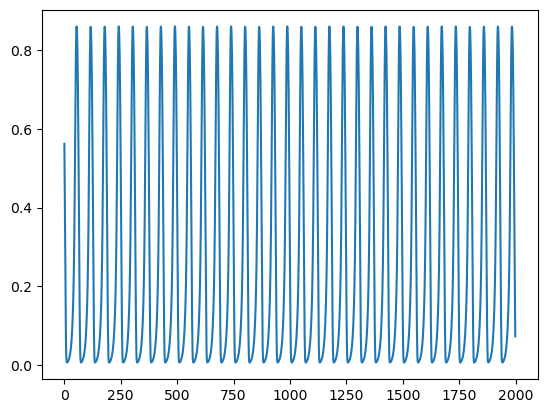

In [68]:
n=6
plt.plot(all_prot_tmp_ode[(n*39993)-2000:(n*39993), 700])

In [ ]:
reducer = umap.UMAP(
        n_neighbors=neighbs,
        min_dist=min_d,
        n_components=2,
        metric='euclidean',
        random_state=5,
        low_memory=True        
        ).fit(all_prot_tmp)

In [84]:
embedding_all_prot = reducer.transform(all_prot_tmp)

In [85]:
win_len = int(window/dt)
all_prot_tmp_ode_ab = np.empty((0,win_len*18))
ab_len = 2000
w_len = len(all_prot_tmp_ode)/len(filenames_sp)
num_ts = int(all_prot_tmp_ode.shape[0]/w_len)

In [86]:
w_len

39993.0

In [87]:
all_prot_tmp_ode.shape

(399930, 720)

In [148]:
win_len = int(window/dt)
all_prot_tmp_ode_ab = np.empty((0,win_len*18))
ab_len = 2000
w_len = len(all_prot_tmp_ode)/len(filenames_sp)
sp = 1
for n in range(len(filenames_sp)):
    tmp = all_prot_tmp_ode[int(sp*w_len-ab_len):int(sp*w_len),:]
    all_prot_tmp_ode_ab = np.append(all_prot_tmp_ode_ab, tmp, axis=0)
    sp += 1

In [149]:
all_prot_tmp_ode_ab.shape

(20000, 720)

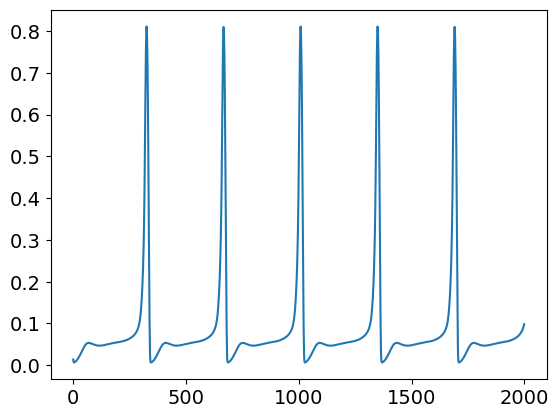

In [150]:
n=6
plt.plot(all_prot_tmp_ode_ab[(n*2000)-2000:(n*2000), 700])

In [151]:
embedding_all_prot_ode = reducer.transform(all_prot_tmp_ode_ab)

In [91]:
trk_len = int(len(embedding_all_prot)/len(filenames_sp))
trk_len_ode = int(len(embedding_all_prot_ode)/len(filenames_sp))

In [92]:
colors_blue = plt.cm.Blues(np.linspace(0,1,5))
colors_red = plt.cm.Reds(np.linspace(0,1,4))
colors_accent = plt.cm.jet(np.linspace(0,1,5))

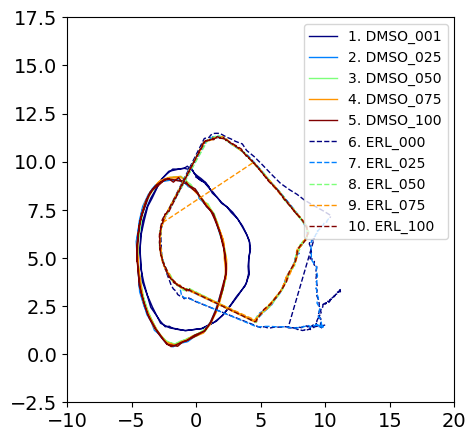

In [152]:
size = (5,5)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

fig = plt.figure(figsize=size)

trk_len = int(len(embedding_all_prot)/len(filenames_sp))
trk_len_ode = int(len(embedding_all_prot_ode)/len(filenames_sp))
n=0
n1=1


plt.plot(embedding_all_prot_ode[(1*trk_len_ode)-100:1*trk_len_ode,0], 
         embedding_all_prot_ode[(1*trk_len_ode)-100:1*trk_len_ode,1], 
         ls='-', lw=1, alpha=1, color=colors_accent[0], label='1. DMSO_001')
plt.plot(embedding_all_prot_ode[(2*trk_len_ode)-100:2*trk_len_ode,0], 
         embedding_all_prot_ode[(2*trk_len_ode)-100:2*trk_len_ode,1], 
         ls='-', lw=1, alpha=1, color=colors_accent[1], label='2. DMSO_025')
plt.plot(embedding_all_prot_ode[(3*trk_len_ode)-100:3*trk_len_ode,0], 
         embedding_all_prot_ode[(3*trk_len_ode)-100:3*trk_len_ode,1], 
         ls='-', lw=1, alpha=1, color=colors_accent[2], label='3. DMSO_050')
plt.plot(embedding_all_prot_ode[(4*trk_len_ode)-100:4*trk_len_ode,0], 
         embedding_all_prot_ode[(4*trk_len_ode)-100:4*trk_len_ode,1], 
         ls='-', lw=1, alpha=1, color=colors_accent[3], label='4. DMSO_075')
plt.plot(embedding_all_prot_ode[(5*trk_len_ode)-100:5*trk_len_ode,0], 
         embedding_all_prot_ode[(5*trk_len_ode)-100:5*trk_len_ode,1], 
         ls='-', lw=1, alpha=1, color=colors_accent[4], label='5. DMSO_100')


plt.plot(embedding_all_prot_ode[(6*trk_len_ode)-100:6*trk_len_ode+120,0], 
         embedding_all_prot_ode[(6*trk_len_ode)-100:6*trk_len_ode+120,1], 
         ls='--', lw=1, alpha=1, color=colors_accent[0], label='6. ERL_000')
plt.plot(embedding_all_prot_ode[(7*trk_len_ode)-100:7*trk_len_ode+120,0], 
         embedding_all_prot_ode[(7*trk_len_ode)-100:7*trk_len_ode+120,1], 
         ls='--', lw=1, alpha=1, color=colors_accent[1], label='7. ERL_025')
plt.plot(embedding_all_prot_ode[(8*trk_len_ode)-100:8*trk_len_ode+70,0], 
         embedding_all_prot_ode[(8*trk_len_ode)-100:8*trk_len_ode+70,1], 
         ls='--', lw=1, alpha=1, color=colors_accent[2], label='8. ERL_050')
plt.plot(embedding_all_prot_ode[(9*trk_len_ode)-100:9*trk_len_ode+55,0], 
         embedding_all_prot_ode[(9*trk_len_ode)-100:9*trk_len_ode+55,1], 
         ls='--', lw=1, alpha=1, color=colors_accent[3], label='9. ERL_075')
plt.plot(embedding_all_prot_ode[(10*trk_len_ode)-100:10*trk_len_ode+55,0], 
         embedding_all_prot_ode[(10*trk_len_ode)-100:10*trk_len_ode+55,1], 
         ls='--', lw=1, alpha=1, color=colors_accent[4], label='10. ERL_100')

plt.xlim(-10,20)
plt.ylim(-2.5, 17.5)

plt.legend()

# plt.savefig(str(SAVE_DIR)+"\\ODEs_jparams.svg", format="svg")


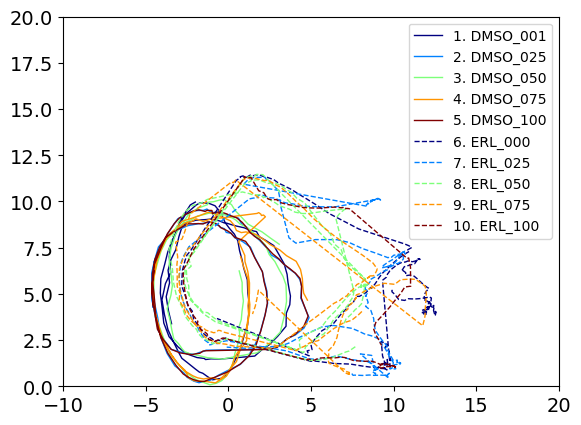

In [99]:
plt.figure()
trk_len = int(len(embedding_all_prot)/len(filenames_sp))
trk_len_ode = int(len(embedding_all_prot_ode)/len(filenames_sp))
n=0
n1=1


plt.plot(embedding_all_prot_ode[0*trk_len_ode:0*trk_len_ode+100,0], 
         embedding_all_prot_ode[0*trk_len_ode:0*trk_len_ode+100,1], 
         ls='-', lw=1, alpha=1, color=colors_accent[0], label='1. DMSO_001')
# plt.plot(embedding_all_prot_ode[1*trk_len_ode:1*trk_len_ode+100,0], 
#          embedding_all_prot_ode[1*trk_len_ode:1*trk_len_ode+100,1], 
#          ls='-', lw=1, alpha=1, color=colors_accent[1], label='2. DMSO_025')
plt.plot(embedding_all_prot_ode[1*trk_len_ode:1*trk_len_ode+60,0], 
         embedding_all_prot_ode[1*trk_len_ode:1*trk_len_ode+60,1], 
         ls='-', lw=1, alpha=1, color=colors_accent[2], label='3. DMSO_050')
# plt.plot(embedding_all_prot_ode[3*trk_len_ode:3*trk_len_ode+46,0], 
#          embedding_all_prot_ode[3*trk_len_ode:3*trk_len_ode+46,1], 
#          ls='-', lw=1, alpha=1, color=colors_accent[3], label='4. DMSO_075')
plt.plot(embedding_all_prot_ode[2*trk_len_ode:2*trk_len_ode+46,0], 
         embedding_all_prot_ode[2*trk_len_ode:2*trk_len_ode+46,1], 
         ls='-', lw=1, alpha=1, color=colors_accent[4], label='5. DMSO_100')


plt.plot(embedding_all_prot_ode[3*trk_len_ode:3*trk_len_ode+1000,0], 
         embedding_all_prot_ode[3*trk_len_ode:3*trk_len_ode+1000,1], 
         ls='--', lw=1, alpha=1, color=colors_accent[0], label='6. ERL_000')
# plt.plot(embedding_all_prot_ode[6*trk_len_ode:5*trk_len_ode+120,0], 
#          embedding_all_prot_ode[6*trk_len_ode:5*trk_len_ode+120,1], 
#          ls='--', lw=1, alpha=1, color=colors_accent[1], label='7. ERL_025')
plt.plot(embedding_all_prot_ode[4*trk_len_ode:4*trk_len_ode+70,0], 
         embedding_all_prot_ode[4*trk_len_ode:4*trk_len_ode+70,1], 
         ls='--', lw=1, alpha=1, color=colors_accent[2], label='6. ERL_050')
# plt.plot(embedding_all_prot_ode[8*trk_len_ode:8*trk_len_ode+55,0], 
#          embedding_all_prot_ode[8*trk_len_ode:8*trk_len_ode+55,1], 
#          ls='--', lw=1, alpha=1, color=colors_accent[3], label='7. ERL_075')
plt.plot(embedding_all_prot_ode[5*trk_len_ode:5*trk_len_ode+55,0], 
         embedding_all_prot_ode[5*trk_len_ode:5*trk_len_ode+55,1], 
         ls='--', lw=1, alpha=1, color=colors_accent[4], label='7. ERL_100')

plt.xlim(-10,20)
plt.ylim(0, 20)

plt.legend()

# plt.savefig(str(SAVE_DIR)+"\\ODEs_jparams.svg", format="svg")


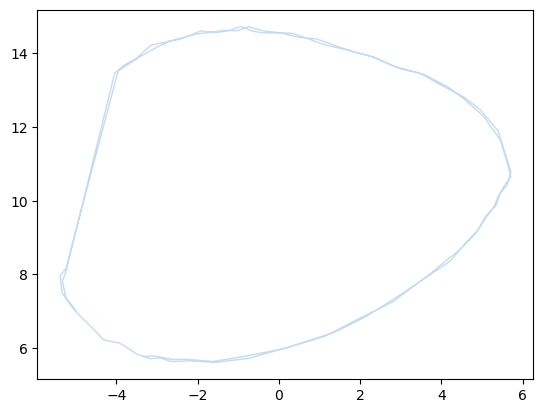

In [29]:
plt.figure()
trk_len = int(len(embedding_all_prot)/len(filenames_sp))
trk_len_ode = int(len(embedding_all_prot_ode)/len(filenames_sp))
n=0
n1=1


plt.plot(embedding_all_prot_ode[1*trk_len_ode:1*trk_len_ode+100,0], 
         embedding_all_prot_ode[1*trk_len_ode:1*trk_len_ode+100,1], 
         ls='-', lw=1, alpha=1, color=colors_blue[1], label='1. DMSO_050')

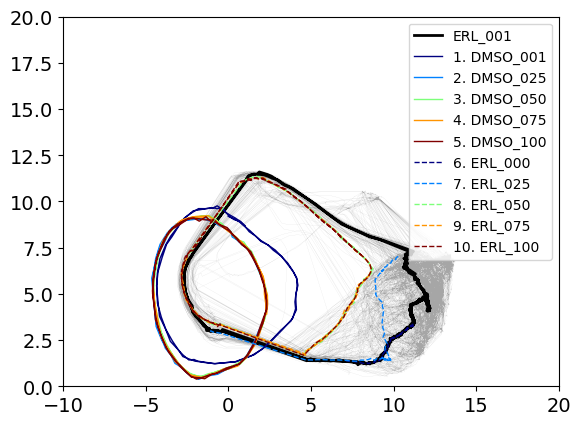

In [167]:
plt.figure()
trk_len = int(len(embedding_all_prot)/len(filenames_sp))
trk_len_ode = int(len(embedding_all_prot_ode)/len(filenames_sp))
n=5
n1=6

plt.plot(embedding_all_prot[n*trk_len:n1*trk_len,0], embedding_all_prot[n*trk_len:n1*trk_len,1], 
         lw=0.05, alpha=0.7, c='gray')

plt.plot(embedding_all_prot_ode[n*trk_len_ode:n*trk_len_ode+1000,0], 
         embedding_all_prot_ode[n*trk_len_ode:n*trk_len_ode+1000,1], 
         ls='-', lw=2, alpha=1, color='black', label='ERL_001')

plt.plot(embedding_all_prot_ode[(1*trk_len_ode)-100:1*trk_len_ode,0], 
         embedding_all_prot_ode[(1*trk_len_ode)-100:1*trk_len_ode,1], 
         ls='-', lw=1, alpha=1, color=colors_accent[0], label='1. DMSO_001')
plt.plot(embedding_all_prot_ode[(2*trk_len_ode)-100:2*trk_len_ode,0], 
         embedding_all_prot_ode[(2*trk_len_ode)-100:2*trk_len_ode,1], 
         ls='-', lw=1, alpha=1, color=colors_accent[1], label='2. DMSO_025')
plt.plot(embedding_all_prot_ode[(3*trk_len_ode)-100:3*trk_len_ode,0], 
         embedding_all_prot_ode[(3*trk_len_ode)-100:3*trk_len_ode,1], 
         ls='-', lw=1, alpha=1, color=colors_accent[2], label='3. DMSO_050')
plt.plot(embedding_all_prot_ode[(4*trk_len_ode)-100:4*trk_len_ode,0], 
         embedding_all_prot_ode[(4*trk_len_ode)-100:4*trk_len_ode,1], 
         ls='-', lw=1, alpha=1, color=colors_accent[3], label='4. DMSO_075')
plt.plot(embedding_all_prot_ode[(5*trk_len_ode)-100:5*trk_len_ode,0], 
         embedding_all_prot_ode[(5*trk_len_ode)-100:5*trk_len_ode,1], 
         ls='-', lw=1, alpha=1, color=colors_accent[4], label='5. DMSO_100')


plt.plot(embedding_all_prot_ode[(6*trk_len_ode)-100:6*trk_len_ode,0], 
         embedding_all_prot_ode[(6*trk_len_ode)-100:6*trk_len_ode,1], 
         ls='--', lw=1, alpha=1, color=colors_accent[0], label='6. ERL_001')
plt.plot(embedding_all_prot_ode[(7*trk_len_ode)-100:7*trk_len_ode,0], 
         embedding_all_prot_ode[(7*trk_len_ode)-100:7*trk_len_ode,1], 
         ls='--', lw=1, alpha=1, color=colors_accent[1], label='7. ERL_025')
plt.plot(embedding_all_prot_ode[(8*trk_len_ode)-100:8*trk_len_ode,0], 
         embedding_all_prot_ode[(8*trk_len_ode)-100:8*trk_len_ode,1], 
         ls='--', lw=1, alpha=1, color=colors_accent[2], label='8. ERL_050')
plt.plot(embedding_all_prot_ode[(9*trk_len_ode)-100:9*trk_len_ode,0], 
         embedding_all_prot_ode[(9*trk_len_ode)-100:9*trk_len_ode,1], 
         ls='--', lw=1, alpha=1, color=colors_accent[3], label='9. ERL_075')
plt.plot(embedding_all_prot_ode[(10*trk_len_ode)-100:10*trk_len_ode,0], 
         embedding_all_prot_ode[(10*trk_len_ode)-100:10*trk_len_ode,1], 
         ls='--', lw=1, alpha=1, color=colors_accent[4], label='10. ERL_100')

plt.xlim(-10,20)
plt.ylim(0, 20)

# plt.xticks(color='w')

plt.legend(loc='upper right')

# plt.savefig(str(SAVE_DIR)+"\\DMSO_001.svg", format="svg")


In [103]:
def restructProt(protDF, embedDF, timeDF):
    peaks_E, _ = find_peaks(protDF.iloc[:,int((win_len*11+win_len/2)-1)], prominence = 40/200, distance = 10)
    peaks_cdc, _ = find_peaks(protDF.iloc[:,int((win_len*17+win_len/2)-1)], prominence = 40/200, distance = 10)
    
    mit_win = pd.DataFrame()
    time_win = pd.DataFrame()
    umap_win = pd.DataFrame()
    num = 1
    
    for n in range(2,len(peaks_cdc)-3):   #make sure we have divisions at ends 
        tmp_mit = peaks_cdc[n]
        tmp_mit2 = peaks_cdc[n+1]
        tmp_mit3 = peaks_cdc[n+2]
        tmp_mit4 = peaks_cdc[n+3]
        
        tmp_g1_s = peaks_E[(tmp_mit < peaks_E) & (peaks_E < tmp_mit2)]
        tmp_g1_s_2 = peaks_E[(tmp_mit2 < peaks_E) & (peaks_E < tmp_mit3)]
        tmp_g1_s_3 = peaks_E[(tmp_mit3 < peaks_E) & (peaks_E < tmp_mit4)]    
             
        if (np.size(tmp_g1_s) > 0) & (np.size(tmp_g1_s_2)>0) & (np.size(tmp_g1_s_3)>0):
            ordered = [tmp_mit, tmp_g1_s[0], tmp_mit2, tmp_g1_s_2[0], tmp_mit3, tmp_g1_s_3[0], tmp_mit4]
            g1_len_tmp = np.array(timeDF.iloc[ordered[3],0]) - np.array(timeDF.iloc[[ordered[2]],0])
            tmp_prot = protDF.iloc[int(ordered[1]):int(ordered[4]),:]
            tmp_umap = embedDF.iloc[int(ordered[1]):int(ordered[4]),:]
            tmp_time = timeDF.iloc[int(ordered[1]):int(ordered[4]),:]
            tmp = [g1_len_tmp]*len(tmp_time)
            tmp_g1s = [int(ordered[1])]*len(tmp_time)
            tmp_mit = [int(ordered[2])]*len(tmp_time)
            tmp_g1s2 = [int(ordered[3])]*len(tmp_time)
            tmp_mit2 = [int(ordered[4])]*len(tmp_time)
            
            tmp_time.insert(0, 'mit2', tmp_mit2)
            tmp_time.insert(0, 'G1-S_2', tmp_g1s2)
            tmp_time.insert(0, 'mit', tmp_mit)
            tmp_time.insert(0, 'G1-S', tmp_g1s)
            tmp_time.insert(0, 'G1_len', tmp)
            tmp_time.insert(0, 'div', [num]*len(tmp_time))
            num += 1
            
            mit_win = pd.concat([mit_win,tmp_prot],ignore_index=True)
            time_win = pd.concat([time_win, tmp_time], ignore_index=True)
            umap_win = pd.concat([umap_win, tmp_umap], ignore_index=True)
            
    return mit_win, time_win, umap_win

In [104]:
trk_len = int(len(all_prot_tmp)/len(filenames_sp))
y_label_list = ['Skp2', 'p21', 'pp21', 'Cdh1', 'Myc', 'CycD', 'CycDp21', 'Rb', 'pRb', 'E2F', 'RbE2F',
                'CycE', 'CycEp21', 'CycA', 'CycAp21', 'CycB', 'CycBp21', 'Cdc20']

dmso_000_prot_df = pd.DataFrame(all_prot_tmp[0*trk_len:1*trk_len,:])
dmso_000_time_df = pd.DataFrame(all_time_tmp[0*trk_len:1*trk_len,:])
dmso_000_emb_df = pd.DataFrame(embedding_all_prot[0*trk_len:1*trk_len,:])

dmso_025_prot_df = pd.DataFrame(all_prot_tmp[1*trk_len:2*trk_len,:])
dmso_025_time_df = pd.DataFrame(all_time_tmp[1*trk_len:2*trk_len,:])
dmso_025_emb_df = pd.DataFrame(embedding_all_prot[1*trk_len:2*trk_len,:])

dmso_050_prot_df = pd.DataFrame(all_prot_tmp[2*trk_len:3*trk_len,:])
dmso_050_time_df = pd.DataFrame(all_time_tmp[2*trk_len:3*trk_len,:])
dmso_050_emb_df = pd.DataFrame(embedding_all_prot[2*trk_len:3*trk_len,:])

dmso_075_prot_df = pd.DataFrame(all_prot_tmp[3*trk_len:4*trk_len,:])
dmso_075_time_df = pd.DataFrame(all_time_tmp[3*trk_len:4*trk_len,:])
dmso_075_emb_df = pd.DataFrame(embedding_all_prot[3*trk_len:4*trk_len,:])

dmso_100_prot_df = pd.DataFrame(all_prot_tmp[4*trk_len:5*trk_len,:])
dmso_100_time_df = pd.DataFrame(all_time_tmp[4*trk_len:5*trk_len,:])
dmso_100_emb_df = pd.DataFrame(embedding_all_prot[4*trk_len:5*trk_len,:])

erl_000_prot_df = pd.DataFrame(all_prot_tmp[5*trk_len:6*trk_len,:])
erl_000_time_df = pd.DataFrame(all_time_tmp[5*trk_len:6*trk_len,:])
erl_000_emb_df = pd.DataFrame(embedding_all_prot[5*trk_len:6*trk_len,:])

erl_025_prot_df = pd.DataFrame(all_prot_tmp[6*trk_len:7*trk_len,:])
erl_025_time_df = pd.DataFrame(all_time_tmp[6*trk_len:7*trk_len,:])
erl_025_emb_df = pd.DataFrame(embedding_all_prot[6*trk_len:7*trk_len,:])

erl_050_prot_df = pd.DataFrame(all_prot_tmp[7*trk_len:8*trk_len,:])
erl_050_time_df = pd.DataFrame(all_time_tmp[7*trk_len:8*trk_len,:])
erl_050_emb_df = pd.DataFrame(embedding_all_prot[7*trk_len:8*trk_len,:])

erl_075_prot_df = pd.DataFrame(all_prot_tmp[8*trk_len:9*trk_len,:])
erl_075_time_df = pd.DataFrame(all_time_tmp[8*trk_len:9*trk_len,:])
erl_075_emb_df = pd.DataFrame(embedding_all_prot[8*trk_len:9*trk_len,:])

erl_100_prot_df = pd.DataFrame(all_prot_tmp[9*trk_len:10*trk_len,:])
erl_100_time_df = pd.DataFrame(all_time_tmp[9*trk_len:10*trk_len,:])
erl_100_emb_df = pd.DataFrame(embedding_all_prot[9*trk_len:10*trk_len,:])


In [105]:
erl_100_prot_df.shape

(39993, 720)

In [109]:
from scipy.signal import find_peaks

In [107]:
mit_win_dmso_000, time_win_dmso_000, umap_win_dmso_000 = restructProt(dmso_000_prot_df, dmso_000_emb_df, dmso_000_time_df)
mit_win_dmso_025, time_win_dmso_025, umap_win_dmso_025 = restructProt(dmso_025_prot_df, dmso_025_emb_df, dmso_025_time_df)
mit_win_dmso_050, time_win_dmso_050, umap_win_dmso_050 = restructProt(dmso_050_prot_df, dmso_050_emb_df, dmso_050_time_df)
mit_win_dmso_075, time_win_dmso_075, umap_win_dmso_075 = restructProt(dmso_075_prot_df, dmso_075_emb_df, dmso_075_time_df)
mit_win_dmso_100, time_win_dmso_100, umap_win_dmso_100 = restructProt(dmso_100_prot_df, dmso_100_emb_df, dmso_100_time_df)
mit_win_erl_000, time_win_erl_000, umap_win_erl_000 = restructProt(erl_000_prot_df, erl_000_emb_df, erl_000_time_df)
mit_win_erl_025, time_win_erl_025, umap_win_erl_025 = restructProt(erl_025_prot_df, erl_025_emb_df, erl_025_time_df)
mit_win_erl_050, time_win_erl_050, umap_win_erl_050 = restructProt(erl_050_prot_df, erl_050_emb_df, erl_050_time_df)
mit_win_erl_075, time_win_erl_075, umap_win_erl_075 = restructProt(erl_075_prot_df, erl_075_emb_df, erl_075_time_df)
mit_win_erl_100, time_win_erl_100, umap_win_erl_100 = restructProt(erl_100_prot_df, erl_100_emb_df, erl_100_time_df)

In [156]:
size = (4,4)
xmin = -10
xmax = 20
ymin = 0
ymax = 20
wid = 1
trk_len_ode = int(len(embedding_all_prot_ode)/len(filenames_sp))
import scipy as sp

[None, None, None, None]

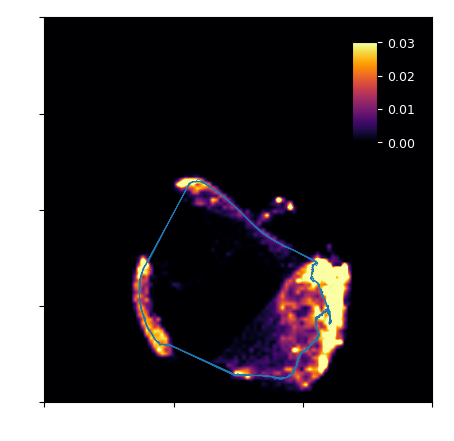

In [157]:
size = (5,5)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

fig = plt.figure(figsize=size)
xmin, xmax = -10, 20
ymin, ymax = 0, 20

x = np.array(umap_win_erl_000[0])
y = np.array(umap_win_erl_000[1])
H, xedges, yedges = np.histogram2d(x, y, bins=100, range= [[xmin,xmax], [ymin,ymax]], density=True)
# Apply gaussian filter
sigma = [3, 3]
H2 = sp.ndimage.filters.gaussian_filter(H, sigma, mode='constant')
#H2[H2>0.01] = 0



ax = fig.gca()

tmp = embedding_all_prot_ode[(5*trk_len_ode):6*trk_len_ode,:]
im = plt.imshow((np.rot90(H)), extent=[xmin, xmax, ymin, ymax], 
                interpolation='bilinear', cmap='inferno', aspect='auto')
im.set_clim(0, 0.03)
plt.plot(tmp[500:,0], tmp[500:,1],
         lw=0.5, alpha=1)

plt.xlim(-10,20)
plt.ylim(0, 20)
plt.xticks(np.arange(-10, 21, step=10))
plt.yticks(np.arange(0, 21, step=5))


plt.xticks(color='w')
plt.yticks(color='w')

cbar_ax = fig.add_axes([0.74, 0.63, 0.05, 0.2])
cb = fig.colorbar(im, cax=cbar_ax)
cb.ax.tick_params(labelsize=9)
cb.ax.yaxis.set_tick_params(color='white')
plt.setp(plt.getp(cb.ax.axes, 'yticklabels'), color='white')

# plt.savefig(str(SAVE_DIR)+"\\DMSO_100_heatmap.svg", format="svg")

In [116]:
sys.path.insert(0, "./../../../Vector_Similarity/python/TS_SS")
from Vector_Similarity import *

2.23606797749979
0.9999999999999998
0.0004639582566999478


In [158]:
w_len = int(len(all_prot_tmp_ode)/len(filenames_sp))


In [159]:
n=5
n1=6

prot_vec=all_prot_tmp[n*w_len:n1*w_len,:]
offset=2
v_len=2

In [160]:
prot_inds = np.arange(n*w_len,n1*w_len,offset)

In [161]:
prot_inds

array([199965, 199967, 199969, ..., 239953, 239955, 239957])

In [162]:
def calc_sim(prot_vec, offset, v_len, prot_inds):
    #prot_inds = np.arange(0,len(prot_vec),offset)
    euc_vals = []
    cos_vals = []
    TS_SS_vals = []
    
    for val in range(len(prot_inds)-2):
        vec1=all_prot_tmp[prot_inds[val]+v_len,:] - all_prot_tmp[prot_inds[val],:]
        vec2=all_prot_tmp[prot_inds[val+1]+v_len,:] - all_prot_tmp[prot_inds[val+1],:]
        euc_vals.append(Euclidean(vec1,vec2))
        cos_vals.append(Cosine(vec1,vec2))
        TS_SS_vals.append(TS_SS(vec1,vec2))
        
    return euc_vals, cos_vals, TS_SS_vals

In [164]:
euc_vals, cos_vals, TS_SS_vals = calc_sim(prot_vec, offset, v_len, prot_inds)

In [165]:
log_euc_vals=[math.log(val) for val in euc_vals]
log_TS_SS_vals=[math.log(val) for val in TS_SS_vals]

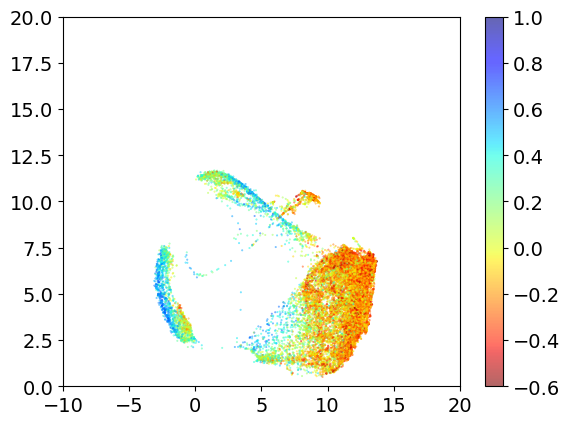

In [166]:
fig1 = plt.figure()

plt.scatter(embedding_all_prot[prot_inds[:-2],0], embedding_all_prot[prot_inds[:-2],1],
           s=0.2, alpha=0.6, vmin=-0.6, vmax=1, c=cos_vals, cmap='jet_r')
plt.ylim(0,20)
plt.xlim(-10,20)
plt.colorbar()

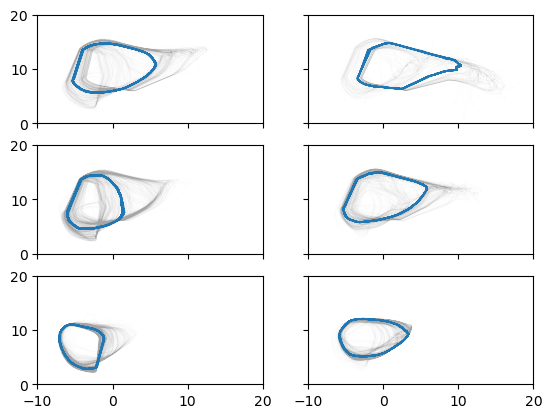

In [92]:
fig = plt.figure()
n1 = 1
for n in range(6):
    plt.subplot(3,2,n1)
    trk_len = int(len(embedding_all_prot)/9)
    trk_len_ode = int(len(embedding_all_prot_ode)/9)
    plt.plot(embedding_all_prot[n*trk_len:n1*trk_len,0], embedding_all_prot[n*trk_len:n1*trk_len,1], lw=0.01, alpha=0.7, c='gray')
    plt.plot(embedding_all_prot_ode[n*trk_len_ode:n1*trk_len_ode,0], embedding_all_prot_ode[n*trk_len_ode:n1*trk_len_ode,1], lw=1, alpha=1)

    plt.xlim(-10,20)
    plt.ylim(0, 20)

    ax = plt.gca()
    if (n1 % 2) == 0:
        ax.yaxis.set_tick_params(labelleft=False)
    if n1<5:
        ax.xaxis.set_tick_params(labelleft=False)
    n1 += 1

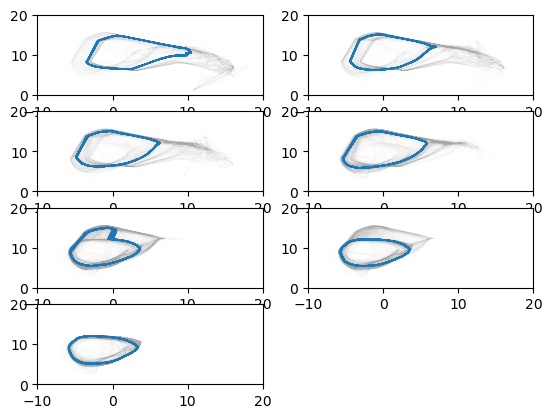

In [161]:
fig = plt.figure()
n1 = 8
fign = 1
for n in range(7,14):
    plt.subplot(4,2,fign)
    trk_len = int(len(embedding_all_prot)/14)
    trk_len_ode = int(len(embedding_all_prot_ode)/14)
    plt.plot(embedding_all_prot[n*trk_len:n1*trk_len,0], embedding_all_prot[n*trk_len:n1*trk_len,1], lw=0.01, alpha=0.7, c='gray')
    plt.plot(embedding_all_prot_ode[n*trk_len_ode:n1*trk_len_ode,0], embedding_all_prot_ode[n*trk_len_ode:n1*trk_len_ode,1], lw=1, alpha=1)

    plt.xlim(-10,20)
    plt.ylim(0, 20)

    ax = plt.gca()
#     if (n1 % 2) == 0:
#         ax.yaxis.set_tick_params(labelleft=False)
#     if n1<5:
#         ax.xaxis.set_tick_params(labelleft=False)
    n1 += 1
    fign += 1

In [38]:
trk_len = int(len(all_prot_tmp)/len(filenames_sp))
y_label_list = ['Skp2', 'p21', 'pp21', 'Cdh1', 'Myc', 'CycD', 'CycDp21', 'Rb', 'pRb', 'E2F', 'RbE2F',
                'CycE', 'CycEp21', 'CycA', 'CycAp21', 'CycB', 'CycBp21', 'Cdc20']
dmso_050_prot_df = pd.DataFrame(all_prot_tmp[0*trk_len:1*trk_len,:])
dmso_050_time_df = pd.DataFrame(all_time_tmp[0*trk_len:1*trk_len,:])
dmso_050_emb_df = pd.DataFrame(embedding_all_prot[0*trk_len:1*trk_len,:])

dmso_007_prot_df = pd.DataFrame(all_prot_tmp[1*trk_len:2*trk_len,:])
dmso_007_time_df = pd.DataFrame(all_time_tmp[1*trk_len:2*trk_len,:])
dmso_007_emb_df = pd.DataFrame(embedding_all_prot[1*trk_len:2*trk_len,:])

dmso_023_prot_df = pd.DataFrame(all_prot_tmp[2*trk_len:3*trk_len,:])
dmso_023_time_df = pd.DataFrame(all_time_tmp[2*trk_len:3*trk_len,:])
dmso_023_emb_df = pd.DataFrame(embedding_all_prot[2*trk_len:3*trk_len,:])

dmso_045_prot_df = pd.DataFrame(all_prot_tmp[3*trk_len:4*trk_len,:])
dmso_045_time_df = pd.DataFrame(all_time_tmp[3*trk_len:4*trk_len,:])
dmso_045_emb_df = pd.DataFrame(embedding_all_prot[3*trk_len:4*trk_len,:])

dmso_085_prot_df = pd.DataFrame(all_prot_tmp[4*trk_len:5*trk_len,:])
dmso_085_time_df = pd.DataFrame(all_time_tmp[4*trk_len:5*trk_len,:])
dmso_085_emb_df = pd.DataFrame(embedding_all_prot[4*trk_len:5*trk_len,:])

erl_006_prot_df = pd.DataFrame(all_prot_tmp[5*trk_len:6*trk_len,:])
erl_006_time_df = pd.DataFrame(all_time_tmp[5*trk_len:6*trk_len,:])
erl_006_emb_df = pd.DataFrame(embedding_all_prot[5*trk_len:6*trk_len,:])

erl_076_prot_df = pd.DataFrame(all_prot_tmp[6*trk_len:7*trk_len,:])
erl_076_time_df = pd.DataFrame(all_time_tmp[6*trk_len:7*trk_len,:])
erl_076_emb_df = pd.DataFrame(embedding_all_prot[6*trk_len:7*trk_len,:])

erl_094_prot_df = pd.DataFrame(all_prot_tmp[7*trk_len:8*trk_len,:])
erl_094_time_df = pd.DataFrame(all_time_tmp[7*trk_len:8*trk_len,:])
erl_094_emb_df = pd.DataFrame(embedding_all_prot[7*trk_len:8*trk_len,:])

In [163]:
trk_len = int(len(all_prot_tmp)/14)
y_label_list = ['Skp2', 'p21', 'pp21', 'Cdh1', 'Myc', 'CycD', 'CycDp21', 'Rb', 'pRb', 'E2F', 'RbE2F',
                'CycE', 'CycEp21', 'CycA', 'CycAp21', 'CycB', 'CycBp21', 'Cdc20']
erl_000_prot_df = pd.DataFrame(all_prot_tmp[7*trk_len:8*trk_len,:])
erl_000_time_df = pd.DataFrame(all_time_tmp[7*trk_len:8*trk_len,:])
erl_000_emb_df = pd.DataFrame(embedding_all_prot[7*trk_len:8*trk_len,:])

erl_020_prot_df = pd.DataFrame(all_prot_tmp[8*trk_len:9*trk_len,:])
erl_020_time_df = pd.DataFrame(all_time_tmp[8*trk_len:9*trk_len,:])
erl_020_emb_df = pd.DataFrame(embedding_all_prot[8*trk_len:9*trk_len,:])

erl_030_prot_df = pd.DataFrame(all_prot_tmp[9*trk_len:10*trk_len,:])
erl_030_time_df = pd.DataFrame(all_time_tmp[9*trk_len:10*trk_len,:])
erl_030_emb_df = pd.DataFrame(embedding_all_prot[9*trk_len:10*trk_len,:])

erl_050_prot_df = pd.DataFrame(all_prot_tmp[10*trk_len:11*trk_len,:])
erl_050_time_df = pd.DataFrame(all_time_tmp[10*trk_len:11*trk_len,:])
erl_050_emb_df = pd.DataFrame(embedding_all_prot[10*trk_len:11*trk_len,:])

erl_065_prot_df = pd.DataFrame(all_prot_tmp[11*trk_len:12*trk_len,:])
erl_065_time_df = pd.DataFrame(all_time_tmp[11*trk_len:12*trk_len,:])
erl_065_emb_df = pd.DataFrame(embedding_all_prot[11*trk_len:12*trk_len,:])

erl_070_prot_df = pd.DataFrame(all_prot_tmp[12*trk_len:13*trk_len,:])
erl_070_time_df = pd.DataFrame(all_time_tmp[12*trk_len:13*trk_len,:])
erl_070_emb_df = pd.DataFrame(embedding_all_prot[12*trk_len:13*trk_len,:])

erl_099_prot_df = pd.DataFrame(all_prot_tmp[13*trk_len:14*trk_len,:])
erl_099_time_df = pd.DataFrame(all_time_tmp[13*trk_len:14*trk_len,:])
erl_099_emb_df = pd.DataFrame(embedding_all_prot[13*trk_len:14*trk_len,:])

In [41]:
def restructProt(protDF, embedDF, timeDF):
    peaks_E, _ = find_peaks(protDF.iloc[:,int((win_len*11+win_len/2)-1)], prominence = 40/200, distance = 10)
    peaks_cdc, _ = find_peaks(protDF.iloc[:,int((win_len*17+win_len/2)-1)], prominence = 40/200, distance = 10)
    
    mit_win = pd.DataFrame()
    time_win = pd.DataFrame()
    umap_win = pd.DataFrame()
    num = 1
    
    for n in range(2,len(peaks_cdc)-3):   #make sure we have divisions at ends 
        tmp_mit = peaks_cdc[n]
        tmp_mit2 = peaks_cdc[n+1]
        tmp_mit3 = peaks_cdc[n+2]
        tmp_mit4 = peaks_cdc[n+3]
        
        tmp_g1_s = peaks_E[(tmp_mit < peaks_E) & (peaks_E < tmp_mit2)]
        tmp_g1_s_2 = peaks_E[(tmp_mit2 < peaks_E) & (peaks_E < tmp_mit3)]
        tmp_g1_s_3 = peaks_E[(tmp_mit3 < peaks_E) & (peaks_E < tmp_mit4)]    
             
        if (np.size(tmp_g1_s) > 0) & (np.size(tmp_g1_s_2)>0) & (np.size(tmp_g1_s_3)>0):
            ordered = [tmp_mit, tmp_g1_s[0], tmp_mit2, tmp_g1_s_2[0], tmp_mit3, tmp_g1_s_3[0], tmp_mit4]
            g1_len_tmp = np.array(timeDF.iloc[ordered[3],0]) - np.array(timeDF.iloc[[ordered[2]],0])
            tmp_prot = protDF.iloc[int(ordered[1]):int(ordered[4]),:]
            tmp_umap = embedDF.iloc[int(ordered[1]):int(ordered[4]),:]
            tmp_time = timeDF.iloc[int(ordered[1]):int(ordered[4]),:]
            tmp = [g1_len_tmp]*len(tmp_time)
            tmp_g1s = [int(ordered[1])]*len(tmp_time)
            tmp_mit = [int(ordered[2])]*len(tmp_time)
            tmp_g1s2 = [int(ordered[3])]*len(tmp_time)
            tmp_mit2 = [int(ordered[4])]*len(tmp_time)
            
            tmp_time.insert(0, 'mit2', tmp_mit2)
            tmp_time.insert(0, 'G1-S_2', tmp_g1s2)
            tmp_time.insert(0, 'mit', tmp_mit)
            tmp_time.insert(0, 'G1-S', tmp_g1s)
            tmp_time.insert(0, 'G1_len', tmp)
            tmp_time.insert(0, 'div', [num]*len(tmp_time))
            num += 1
            
            mit_win = pd.concat([mit_win,tmp_prot],ignore_index=True)
            time_win = pd.concat([time_win, tmp_time], ignore_index=True)
            umap_win = pd.concat([umap_win, tmp_umap], ignore_index=True)
            
    return mit_win, time_win, umap_win

In [39]:
from scipy.signal import find_peaks
from numpy.linalg import norm
import multiprocess as mp
import time

In [97]:
mit_win_dmso_060, time_win_dmso_060, umap_win_dmso_060 = restructProt(dmso_060_prot_df, dmso_060_emb_df, dmso_060_time_df)
mit_win_dmso_065, time_win_dmso_065, umap_win_dmso_065 = restructProt(dmso_065_prot_df, dmso_065_emb_df, dmso_065_time_df)
mit_win_dmso_070, time_win_dmso_070, umap_win_dmso_070 = restructProt(dmso_070_prot_df, dmso_070_emb_df, dmso_070_time_df)

In [166]:
mit_win_dmso_000, time_win_dmso_000, umap_win_dmso_000 = restructProt(dmso_000_prot_df, dmso_000_emb_df, dmso_000_time_df)
mit_win_dmso_020, time_win_dmso_020, umap_win_dmso_020 = restructProt(dmso_020_prot_df, dmso_020_emb_df, dmso_020_time_df)
mit_win_dmso_030, time_win_dmso_030, umap_win_dmso_030 = restructProt(dmso_030_prot_df, dmso_030_emb_df, dmso_030_time_df)
mit_win_dmso_050, time_win_dmso_050, umap_win_dmso_050 = restructProt(dmso_050_prot_df, dmso_050_emb_df, dmso_050_time_df)
mit_win_dmso_065, time_win_dmso_065, umap_win_dmso_065 = restructProt(dmso_065_prot_df, dmso_065_emb_df, dmso_065_time_df)
mit_win_dmso_070, time_win_dmso_070, umap_win_dmso_070 = restructProt(dmso_070_prot_df, dmso_070_emb_df, dmso_070_time_df)
mit_win_dmso_099, time_win_dmso_099, umap_win_dmso_099 = restructProt(dmso_099_prot_df, dmso_099_emb_df, dmso_099_time_df)

In [167]:
mit_win_erl_000, time_win_erl_000, umap_win_erl_000 = restructProt(erl_000_prot_df, erl_000_emb_df, erl_000_time_df)
mit_win_erl_020, time_win_erl_020, umap_win_erl_020 = restructProt(erl_020_prot_df, erl_020_emb_df, erl_020_time_df)
mit_win_erl_030, time_win_erl_030, umap_win_erl_030 = restructProt(erl_030_prot_df, erl_030_emb_df, erl_030_time_df)
mit_win_erl_050, time_win_erl_050, umap_win_erl_050 = restructProt(erl_050_prot_df, erl_050_emb_df, erl_050_time_df)
mit_win_erl_065, time_win_erl_065, umap_win_erl_065 = restructProt(erl_065_prot_df, erl_065_emb_df, erl_065_time_df)
mit_win_erl_070, time_win_erl_070, umap_win_erl_070 = restructProt(erl_070_prot_df, erl_070_emb_df, erl_070_time_df)
mit_win_erl_099, time_win_erl_099, umap_win_erl_099 = restructProt(erl_099_prot_df, erl_099_emb_df, erl_099_time_df)

In [188]:
mit_win_dmso_050, time_win_dmso_050, umap_win_dmso_050 = restructProt(dmso_050_prot_df, dmso_050_emb_df, dmso_050_time_df)
mit_win_dmso_000, time_win_dmso_000, umap_win_dmso_000 = restructProt(dmso_000_prot_df, dmso_000_emb_df, dmso_000_time_df)
mit_win_dmso_030, time_win_dmso_030, umap_win_dmso_030 = restructProt(dmso_030_prot_df, dmso_030_emb_df, dmso_030_time_df)
mit_win_dmso_070, time_win_dmso_070, umap_win_dmso_070 = restructProt(dmso_070_prot_df, dmso_070_emb_df, dmso_070_time_df)
mit_win_dmso_099, time_win_dmso_099, umap_win_dmso_099 = restructProt(dmso_099_prot_df, dmso_099_emb_df, dmso_099_time_df)
mit_win_erl_000, time_win_erl_000, umap_win_erl_000 = restructProt(erl_000_prot_df, erl_000_emb_df, erl_000_time_df)
mit_win_erl_050, time_win_erl_050, umap_win_erl_050 = restructProt(erl_050_prot_df, erl_050_emb_df, erl_050_time_df)
mit_win_erl_099, time_win_erl_099, umap_win_erl_099 = restructProt(erl_099_prot_df, erl_099_emb_df, erl_099_time_df)

In [42]:
mit_win_dmso_050, time_win_dmso_050, umap_win_dmso_050 = restructProt(dmso_050_prot_df, dmso_050_emb_df, dmso_050_time_df)
mit_win_dmso_007, time_win_dmso_007, umap_win_dmso_007 = restructProt(dmso_007_prot_df, dmso_007_emb_df, dmso_007_time_df)
mit_win_dmso_023, time_win_dmso_023, umap_win_dmso_023 = restructProt(dmso_023_prot_df, dmso_023_emb_df, dmso_023_time_df)
mit_win_dmso_045, time_win_dmso_045, umap_win_dmso_045 = restructProt(dmso_045_prot_df, dmso_045_emb_df, dmso_045_time_df)
mit_win_dmso_085, time_win_dmso_085, umap_win_dmso_085 = restructProt(dmso_085_prot_df, dmso_085_emb_df, dmso_085_time_df)
mit_win_erl_006, time_win_erl_006, umap_win_erl_006 = restructProt(erl_006_prot_df, erl_006_emb_df, erl_006_time_df)
mit_win_erl_076, time_win_erl_076, umap_win_erl_076 = restructProt(erl_076_prot_df, erl_076_emb_df, erl_076_time_df)
mit_win_erl_094, time_win_erl_094, umap_win_erl_094 = restructProt(erl_094_prot_df, erl_094_emb_df, erl_094_time_df)

In [43]:
def calc_distances(ode_proj, ode_wind, stoch_proj, stoch_wind, time_win):
    all_d_proj = []
    for row in range(len(stoch_proj)):
        difs = [norm(stoch_proj.iloc[row].to_numpy() - ode_proj[n,:]) for n in range(len(ode_proj))]
        min_d = min(difs)
        all_d_proj.append(min_d)
        if (row%10000) == 0:
            print(row)
    
    all_d = []
#     for n in time_win['div'].unique():
#         tmpDF = time_win.loc[time_win['div'] == n]
#         tmp = np.array(stoch_wind.iloc[tmpDF.iloc[0,3]:tmpDF.iloc[0,5],:])
#         tmp_umap = np.array(umapDF.iloc[tmpDF.index[0]:tmpDF.index[-1],:])
    for row in range(len(stoch_wind)):
        difs = [norm(np.array(stoch_wind.iloc[row,:]) - ode_wind[n,:]) for n in range(len(ode_wind))]
        min_d = min(difs)
        all_d.append(min_d)
        if (row%10000) == 0:
            print(row)
        
    return all_d_proj, all_d

In [65]:
ode_proj_umap = embedding_all_prot_ode[7*trk_len_ode:7*trk_len_ode+200,:]
ode_wind = all_prot_tmp_ode_ab[7*trk_len_ode:7*trk_len_ode+200,:]
stoch_proj_umap = umap_win_dmso_050
stoch_wind = mit_win_dmso_050
time_win = time_win_dmso_050
rows = list(range(len(stoch_proj_umap)))


In [66]:
def calc_dis_proj_umap(row, stoch_proj_umap=stoch_proj_umap, ode_proj_umap=ode_proj_umap, norm=norm):
    difs = [norm(stoch_proj_umap.iloc[row].to_numpy() - ode_proj_umap[n,:]) for n in range(len(ode_proj_umap))]
    min_d = min(difs)
    return min_d

def calc_dis_win(row, stoch_wind=stoch_wind, ode_wind=ode_wind, norm=norm, np=np):
    difs = [norm(np.array(stoch_wind.iloc[row,:]) - ode_wind[n,:]) for n in range(len(ode_wind))]
    min_d = min(difs)
    return min_d

In [67]:
start = time.time()
with mp.Pool(processes = 12) as p:
    results_proj_d050_e094_umap = p.map(calc_dis_proj_umap, rows)

with mp.Pool(processes = 12) as p:
    results_d050_e094_wind = p.map(calc_dis_win, rows)
end = time.time()
print(end - start)


229.30099391937256


In [68]:
def plotDistHist(data, color='black', linewidth=1, bw=0.02, lim=6, label='DistHist'):
    xbins = np.arange(0, lim + bw, bw)
    
    _, _, his1= plt.hist(data, bins=xbins, color=color, linewidth=linewidth, histtype=u'step', 
                         density=True, label=label)
    return his1
def plotDistHistCDF(data, color='black', linewidth=1, bw=0.02, lim=6, label='DistHist'):
    xbins = np.arange(0, lim + bw, bw)
    
    _, _, his1= plt.hist(data, bins=xbins, color=color, linewidth=linewidth, histtype=u'step', density=True, 
                         cumulative=True, label=label)
    return his1

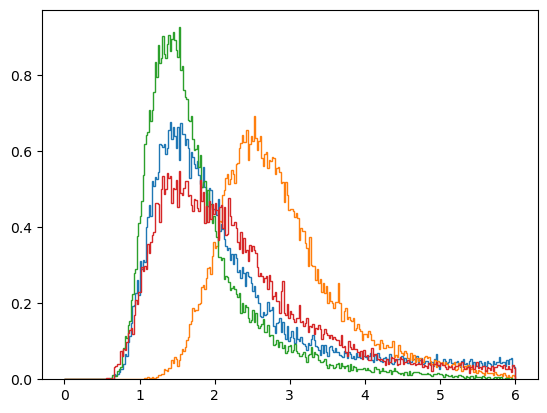

In [226]:
his1= plotDistHist(results_d050_d050_wind, color='tab:blue')
his1= plotDistHist(results_d050_e050_wind, color='tab:orange')
his1= plotDistHist(results_d050_d030_wind, color='tab:green')
his1= plotDistHist(results_d050_d070_wind, color='tab:red')




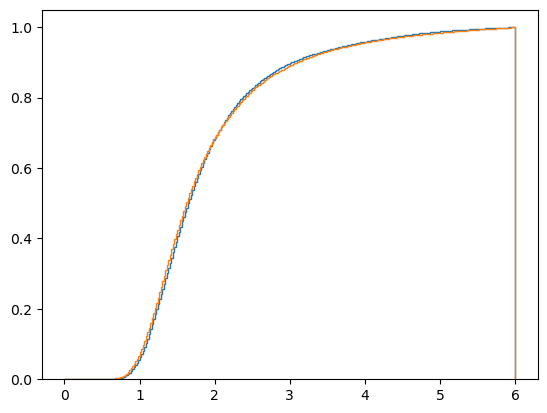

In [114]:
his1= plotDistHistCDF(results_d065_d060_wind, color='tab:blue')
his1= plotDistHistCDF(results_d065_d070_wind, color='tab:orange')



In [ ]:
his1= plotDistHistCDF(results_060_wind, color='blue')
his1= plotDistHistCDF(results_060_072_wind, color='green')



In [197]:
traj_dists = [results_e000_d000_wind, results_e000_e000_wind]
td_arr = np.array(traj_dists)

In [69]:
def close_traj(traj_dists):
    num_trajs = list(range(len(traj_dists)))
    td_arr = np.array(traj_dists)  
    mins = []
    min_vals = []
    
    for traj in range(td_arr.shape[1]):
        mins.append(np.argmin(td_arr[:,traj]))
        min_vals.append(np.amin(td_arr[:,traj]))
        
    return mins, min_vals
            

In [320]:
test, test_vals = close_traj(traj_dists)

In [200]:
stoch_proj_umap['Closest'] = test

In [ ]:
stoch_proj_umap.loc[stoch_proj_umap['Closest'] == 0]

In [227]:
fig = plt.figure()
trk_len = int(len(embedding_all_prot)/14)
trk_len_ode = int(len(embedding_all_prot_ode)/14)
embedding_tmp = embedding_all_prot[0*trk_len:1*trk_len,:]
stoch_d00 = stoch_proj_umap.loc[stoch_proj_umap['Closest'] == 0]
stoch_e00 = stoch_proj_umap.loc[stoch_proj_umap['Closest'] == 1]
plt.scatter(stoch_d00[0], stoch_d00[1], s=0.2, alpha=0.1)
plt.scatter(stoch_e00[0], stoch_e00[1], s=0.2, alpha=0.1)
# plt.plot(embedding_all_prot[6*trk_len:7*trk_len,0], embedding_all_prot[6*trk_len:7*trk_len,1], lw=0.01, alpha=0.7, c='gray')
# plt.plot(embedding_all_prot_ode[6*trk_len_ode:7*trk_len_ode,0], embedding_all_prot_ode[6*trk_len_ode:7*trk_len_ode,1], lw=1, alpha=1)
plt.plot(embedding_all_prot_ode[0*trk_len_ode:1*trk_len_ode,0], embedding_all_prot_ode[0*trk_len_ode:1*trk_len_ode,1], lw=0.1, alpha=1)
plt.plot(embedding_all_prot_ode[7*trk_len_ode:8*trk_len_ode,0], embedding_all_prot_ode[7*trk_len_ode:8*trk_len_ode,1], lw=0.1, alpha=1)


plt.xlim(-10,20)
plt.ylim(0, 20)

KeyError: 'Closest'

<Figure size 640x480 with 0 Axes>

In [202]:
len(stoch_d00)

2168

In [75]:
traj_dists = [results_d050_d050_wind, results_d050_d007_wind, results_d050_d023_wind, 
              results_d050_d045_wind, results_d050_d085_wind, results_d050_e006_wind,
              results_d050_e076_wind, results_d050_e094_wind]
td_arr = np.array(traj_dists)


In [77]:
test, test_vals = close_traj(traj_dists)


In [78]:
stoch_proj_umap['Closest'] = test

(0.0, 20.0)

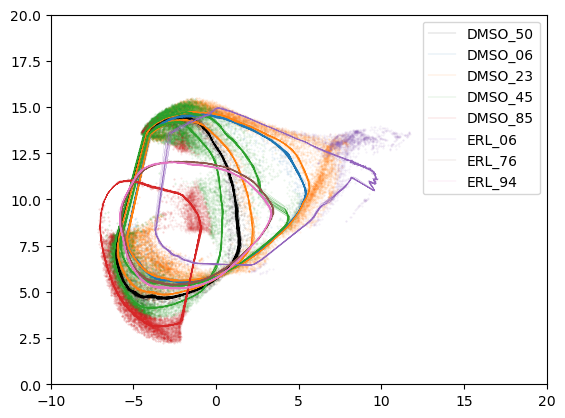

In [80]:
fig = plt.figure()
trk_len = int(len(embedding_all_prot)/len(filenames_sp))
trk_len_ode = int(len(embedding_all_prot_ode)/len(filenames_sp))

stoch_d50 = stoch_proj_umap.loc[stoch_proj_umap['Closest'] == 0]

stoch_d07 = stoch_proj_umap.loc[stoch_proj_umap['Closest'] == 1]
stoch_d23 = stoch_proj_umap.loc[stoch_proj_umap['Closest'] == 2]
stoch_d45 = stoch_proj_umap.loc[stoch_proj_umap['Closest'] == 3]
stoch_d85 = stoch_proj_umap.loc[stoch_proj_umap['Closest'] == 4]
stoch_e06 = stoch_proj_umap.loc[stoch_proj_umap['Closest'] == 5]
stoch_e76 = stoch_proj_umap.loc[stoch_proj_umap['Closest'] == 6]
stoch_e94 = stoch_proj_umap.loc[stoch_proj_umap['Closest'] == 7]

plt.scatter(stoch_d50[0], stoch_d50[1], s=0.2, alpha=0.1, color='black')

plt.scatter(stoch_d07[0], stoch_d07[1], s=0.2, alpha=0.1)
plt.scatter(stoch_d23[0], stoch_d23[1], s=0.2, alpha=0.1)
plt.scatter(stoch_d45[0], stoch_d45[1], s=0.2, alpha=0.1)
plt.scatter(stoch_d85[0], stoch_d85[1], s=0.2, alpha=0.1)
plt.scatter(stoch_e06[0], stoch_e06[1], s=0.2, alpha=0.1)
plt.scatter(stoch_e76[0], stoch_e76[1], s=0.2, alpha=0.1)
plt.scatter(stoch_e94[0], stoch_e94[1], s=0.2, alpha=0.1)

# plt.plot(embedding_all_prot[6*trk_len:7*trk_len,0], embedding_all_prot[6*trk_len:7*trk_len,1], lw=0.01, alpha=0.7, c='gray')
# plt.plot(embedding_all_prot_ode[6*trk_len_ode:7*trk_len_ode,0], embedding_all_prot_ode[6*trk_len_ode:7*trk_len_ode,1], lw=1, alpha=1)
plt.plot(embedding_all_prot_ode[0*trk_len_ode:1*trk_len_ode,0], embedding_all_prot_ode[0*trk_len_ode:1*trk_len_ode,1], lw=0.1, alpha=1, color='black', label='DMSO_50')

plt.plot(embedding_all_prot_ode[1*trk_len_ode:2*trk_len_ode,0], embedding_all_prot_ode[1*trk_len_ode:2*trk_len_ode,1], lw=0.1, alpha=1, label='DMSO_06')
plt.plot(embedding_all_prot_ode[2*trk_len_ode:3*trk_len_ode,0], embedding_all_prot_ode[2*trk_len_ode:3*trk_len_ode,1], lw=0.1, alpha=1, label='DMSO_23')
plt.plot(embedding_all_prot_ode[3*trk_len_ode:4*trk_len_ode,0], embedding_all_prot_ode[3*trk_len_ode:4*trk_len_ode,1], lw=0.1, alpha=1, label='DMSO_45')
plt.plot(embedding_all_prot_ode[4*trk_len_ode:5*trk_len_ode,0], embedding_all_prot_ode[4*trk_len_ode:5*trk_len_ode,1], lw=0.1, alpha=1, label='DMSO_85')
plt.plot(embedding_all_prot_ode[5*trk_len_ode:6*trk_len_ode,0], embedding_all_prot_ode[5*trk_len_ode:6*trk_len_ode,1], lw=0.1, alpha=1, label='ERL_06')
plt.plot(embedding_all_prot_ode[6*trk_len_ode:7*trk_len_ode,0], embedding_all_prot_ode[6*trk_len_ode:7*trk_len_ode,1], lw=0.1, alpha=1, label='ERL_76')
plt.plot(embedding_all_prot_ode[7*trk_len_ode:8*trk_len_ode,0], embedding_all_prot_ode[7*trk_len_ode:8*trk_len_ode,1], lw=0.1, alpha=1, label='ERL_94')

plt.legend()
plt.xlim(-10,20)
plt.ylim(0, 20)

In [81]:
len(stoch_d50)

4909

In [82]:
len(stoch_d07)

2133

In [85]:
len(stoch_d23)

16503

In [86]:
len(stoch_d45)

20154

In [87]:
len(stoch_d85)

9164

In [88]:
len(stoch_e06)

2019

In [89]:
len(stoch_e76)

88

In [90]:
len(stoch_e94)

64

In [322]:
min7 = test_vals

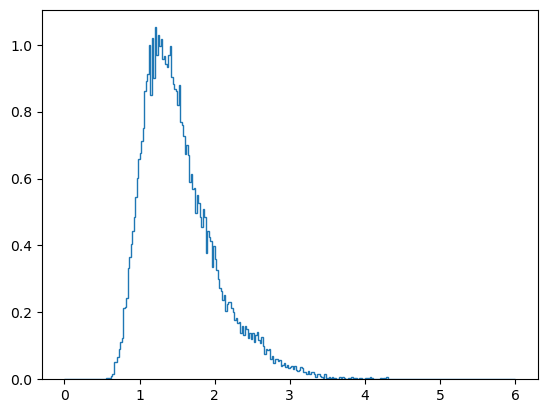

In [326]:
his1= plotDistHist(min7, color='tab:blue')

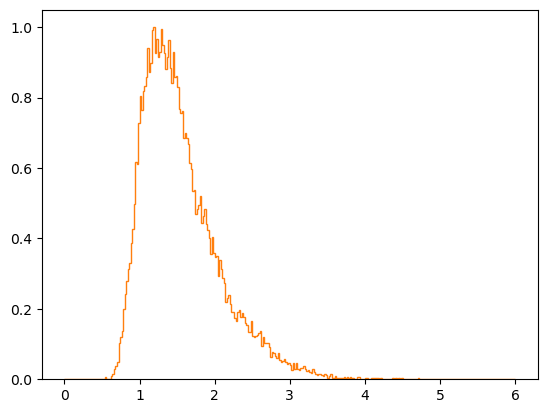

In [91]:
his1= plotDistHist(test_vals, color='tab:orange')